# 2. Hough Transform

Practice for the Hough module: line detection with the (ρ, θ) accumulator, the effect of the cell size
(and voting into a small patch of cells when edges are inaccurate), and the generalized Hough transform with
an R-table indexed by edge direction, which finds an arbitrary shape.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

## 2.1 Line accumulator and cell size

Two nearly parallel lines 4 px apart, with edge noise. Big cells merge them into one peak; tiny cells
scatter the votes so no single cell stands out. Letting each point vote into a 3×3 patch of fine cells
brings the peaks back.

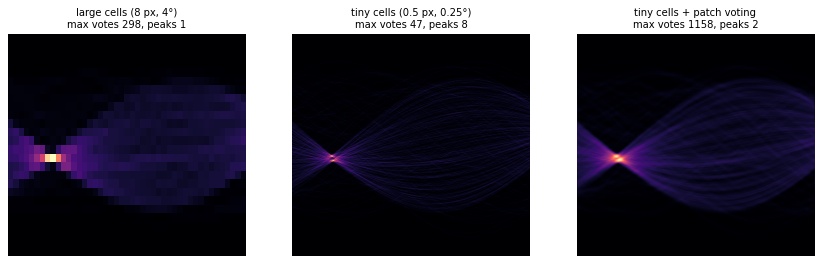

In [2]:
def line_points(rho, th, n=150, noise=0.7):
    t = rng.uniform(-60, 60, n)
    x = rho * np.cos(th) - t * np.sin(th) + 64; y = rho * np.sin(th) + t * np.cos(th) + 64
    return np.c_[x, y] + rng.normal(0, noise, (n, 2))

pts = np.vstack([line_points(10, np.deg2rad(30)), line_points(14, np.deg2rad(31)), rng.uniform(0, 128, (100, 2))])

def hough(pts, d_rho, d_th, spread=0):
    ths = np.deg2rad(np.arange(0, 180, d_th)); rmax = 100
    acc = np.zeros((int(2 * rmax / d_rho) + 1, len(ths)))
    rho = (pts[:, :1] - 64) * np.cos(ths) + (pts[:, 1:] - 64) * np.sin(ths)
    ri = np.round((rho + rmax) / d_rho).astype(int); ti = np.broadcast_to(np.arange(len(ths)), ri.shape)
    for dr in range(-spread, spread + 1):
        for dt in range(-spread, spread + 1):
            np.add.at(acc, ((ri + dr).clip(0, acc.shape[0] - 1), (ti + dt) % len(ths)), 1)
    return acc

def n_peaks(acc, frac=0.6):
    """count separated local maxima above frac * max"""
    from numpy.lib.stride_tricks import sliding_window_view
    P = np.pad(acc, 2, constant_values=-1)
    mx = sliding_window_view(P, (5, 5)).max((-2, -1))
    return int(((acc == mx) & (acc >= frac * acc.max())).sum())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (dr, dth, sp, t) in zip(axes, [(8, 4, 0, "large cells (8 px, 4°)"), (0.5, 0.25, 0, "tiny cells (0.5 px, 0.25°)"), (0.5, 0.25, 3, "tiny cells + patch voting")]):
    acc = hough(pts, dr, dth, sp)
    ax.imshow(acc, aspect="auto", cmap="magma"); ax.set_title(f"{t}\nmax votes {acc.max():.0f}, peaks {n_peaks(acc)}", fontsize=9); ax.axis("off")
plt.show()

## 2.2 Generalized Hough transform

For a shape with no simple formula, store an R-table: for every edge point of a template, index by its edge
direction φ and save the vector `(r, α)` to a reference point. To detect, every edge point in the image looks
up its φ and votes for the reference points it implies. A rotated shape would shift φ and α by the rotation
angle while r stays the same, so rotation adds one more accumulator dimension.

true reference points: [(40, 45), (95, 80)] | found: [(95, 80), (40, 45)]


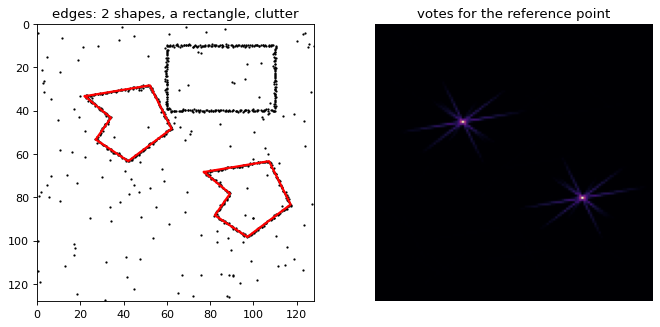

In [3]:
def polygon_edges(verts, step=0.5):
    pts, phis = [], []
    for p, q in zip(verts, np.roll(verts, -1, 0)):
        n = int(np.linalg.norm(q - p) / step)
        t = np.linspace(0, 1, n, endpoint=False)[:, None]
        pts.append(p + t * (q - p))
        d = q - p; phis.append(np.full(n, np.arctan2(d[1], d[0]) % np.pi))     # tangent direction
    return np.vstack(pts), np.concatenate(phis)

shape = np.array([[0, 0], [30, -5], [40, 15], [20, 30], [5, 20], [12, 10]], float)
ref = shape.mean(0)
tp, tphi = polygon_edges(shape)
n_bins = 36
bin_of = lambda phi: (np.round(phi / np.pi * n_bins).astype(int)) % n_bins
r_table = {b: [] for b in range(n_bins)}
for p, b in zip(tp, bin_of(tphi)):
    r_table[b].append(ref - p)                    # stored as a vector = (r, α) in Cartesian form

true_refs = [np.array([40.0, 45.0]), np.array([95.0, 80.0])]
ep, ephi = [], []
for c in true_refs:
    p, ph = polygon_edges(shape - ref + c); ep.append(p); ephi.append(ph)
other, ophi = polygon_edges(np.array([[60, 10], [110, 10], [110, 40], [60, 40]], float))   # a rectangle (distractor)
clutter = rng.uniform(0, 128, (150, 2)); cphi = rng.uniform(0, np.pi, 150)
ep = np.vstack(ep + [other, clutter]) + rng.normal(0, 0.3, (len(np.vstack(ep)) + len(other) + 150, 2))
ephi = np.concatenate(ephi + [ophi, cphi])

acc = np.zeros((128, 128))
for p, b in zip(ep, bin_of(ephi)):
    for vec in r_table[b]:
        x, y = np.round(p + vec).astype(int)
        if 0 <= x < 128 and 0 <= y < 128: acc[y, x] += 1
found, A = [], acc.copy()
for _ in range(2):
    y, x = np.unravel_index(A.argmax(), A.shape); found.append((int(x), int(y))); A[y - 8:y + 9, x - 8:x + 9] = 0
print("true reference points:", [tuple(map(int, c)) for c in true_refs], "| found:", found)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].scatter(*ep.T, s=1, c="k"); axes[0].set_xlim(0, 128); axes[0].set_ylim(128, 0); axes[0].set_aspect("equal")
for x, y in found:
    axes[0].plot(*np.r_[shape - ref + [x, y], (shape - ref + [x, y])[:1]].T, "r", lw=2)
axes[0].set_title("edges: 2 shapes, a rectangle, clutter")
axes[1].imshow(acc, cmap="magma"); axes[1].set_title("votes for the reference point"); axes[1].axis("off")
plt.show()